# Nuclei segmentation: annotations, models and one controlled experiment

Compare two real H&E patches with annotated ground truth, HoVer-NeXt and Cellpose, then change only Cellpose input polarity on one patch. Annotation conversion and saved results follow the comparisons. UNI is an encoder, covered in the [classification notebook](wsi_classification_demo.ipynb), and is not run here.

**Preprocessing and evaluation settings are scientific choices.** These two illustrative patches cannot rank models or establish generalization; physical scale is unverified, crop-edge objects are truncated, and training-data overlap has not been ruled out. Review stain/tissue suitability, annotation handling and model assumptions for the intended question.

## 1. Preflight and inputs

Use the locked main `.venv` kernel with the [pretrained setup](../docs/pretrained-models.md); install the separate locked Cellpose environment before running. The first cell checks local inputs and calls repository scripts only for missing public datasets or required weights. Existing sources are preserved; optional gated UNI is never downloaded. First-time NuInsSeg acquisition is approximately 1.63 GB. No packages are installed by this notebook. Preflight verifies weights, imports both environments and checks a writable output/cache location **before inference**.

Bounds: one COCO image (JSON ≤64 MB), one 512 × 512 NuInsSeg image, two 256 × 256 model patches, one CPU thread. A top-to-bottom run makes **five model calls**: four baseline calls and one fixed polarity experiment. Automated validation records its per-cell timeout in the execution receipt; Cellpose also has a worker timeout. Interactive HoVer-NeXt calls have no built-in wall-clock interrupt.

Each inference call creates a new attempt directory. Re-executing a prediction cell preserves the old result. Restart the kernel before changing the PyTorch thread policy.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
for key in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[key] = '1'

from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('png')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT = None  # Set Path(...) if launching outside this checkout.
if PROJECT is None:
    PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'pyproject.toml').is_file() and (p / 'src/annotations.py').is_file()), None)
if PROJECT is None:
    raise FileNotFoundError('Open from this checkout or set PROJECT explicitly.')
PROJECT = Path(PROJECT).resolve(strict=True)
sys.path.insert(0, str(PROJECT))
subprocess.run([sys.executable, str(PROJECT / 'scripts/prepare_demo_inputs.py'),
                '--demo', 'segmentation'], check=True, cwd=PROJECT)
from src.metrics import comparison_row
from src.segmentation_demo import prepare_demo, load_demo_patches, run_prediction, plot_polarity, export_demo, plot_model_comparison, postprocess_prediction, plot_postprocessing

OUTPUT_ROOT = None  # Default: ignored outputs/annotation_segmentation_demo/ in this project.
demo = prepare_demo(PROJECT, output_root=OUTPUT_ROOT)
patches = load_demo_patches(demo)
baseline = {}
display(pd.DataFrame(demo['preflight']))
print('Fresh run:', demo['out'])
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

Matplotlib is building the font cache; this may take a moment.


{
  "demo": "segmentation",
  "project": "/Users/irina/Projects/digital-pathology-demo",
  "commands_run": [],
  "missing": [],
  "datasets": {
    "cytonuke": {
      "integrity_check": "required nonempty bounded files; notebook validates content",
      "missing_before": []
    },
    "nuinsseg": {
      "integrity_check": "required nonempty bounded files; notebook validates content",
      "missing_before": []
    }
  },
  "models": {
    "hovernext": {
      "integrity_check": "pinned size and SHA-256",
      "missing_before": []
    },
    "cellpose": {
      "integrity_check": "pinned size and SHA-256",
      "missing_before": []
    }
  },
  "status": "ready"
}


,component,status,detail
0,Main Python / PyTorch,ready,2.12.1
1,HoVer-NeXt weights,verified,PanNuke Tiny fold 1; CPU
2,Cellpose environment / weights,verified,3.1.1.2; nucleitorch_0; CPU
3,Output / Numba cache,writable,/Users/irina/Projects/digital-pathology-demo/o...


Fresh run: /Users/irina/Projects/digital-pathology-demo/outputs/pipeline-audit-20261103/segmentation-dedup-publish-validation/runs/20261103T184725Z_crbelr6s


## 2. Two patches, two pretrained models

CytoNuke uses its entire 256 × 256 RGB image. **Category 0 is NUCLEUS**, not background; whole-cell category 1 is not scored. Its annotated raster uses declared last-wins handling of overlapping polygons. NuInsSeg uses the centre crop `(x, y, width, height) = (128, 128, 256, 256)` from `human_bladder_01`. RGB, authors-recommended **`label masks modify`**, and ambiguity are cropped identically without resizing or renumbering. Raw `label masks` can assign extra numbers to overlaps and are not used as separate nuclei.

HoVer-NeXt uses the pinned PanNuke ConvNeXtV2 Tiny fold-1 model, RGB/255, upstream thresholds, one direct patch and no stain normalization or test-time augmentation. Its 0.25 µm/pixel training assumption is not verified for these PNGs; no physical scale or resizing is inferred. Cellpose 3 uses `nucleitorch_0`, grayscale channels `(0, 0)`, percentile normalization, **diameter=17 input pixels** and `invert=False`. These defaults are not an H&E calibration.

Each row keeps the same patch and coordinates; columns show RGB, annotated ground truth and both predictions. Solid cyan denotes ground truth, dashed orange predictions and grey ignored ambiguity. A zero-object prediction is shown explicitly. Models receive RGB only: annotations never enter inference. We inspect instance masks, not HoVer-NeXt cell-type classes or calibrated confidence.

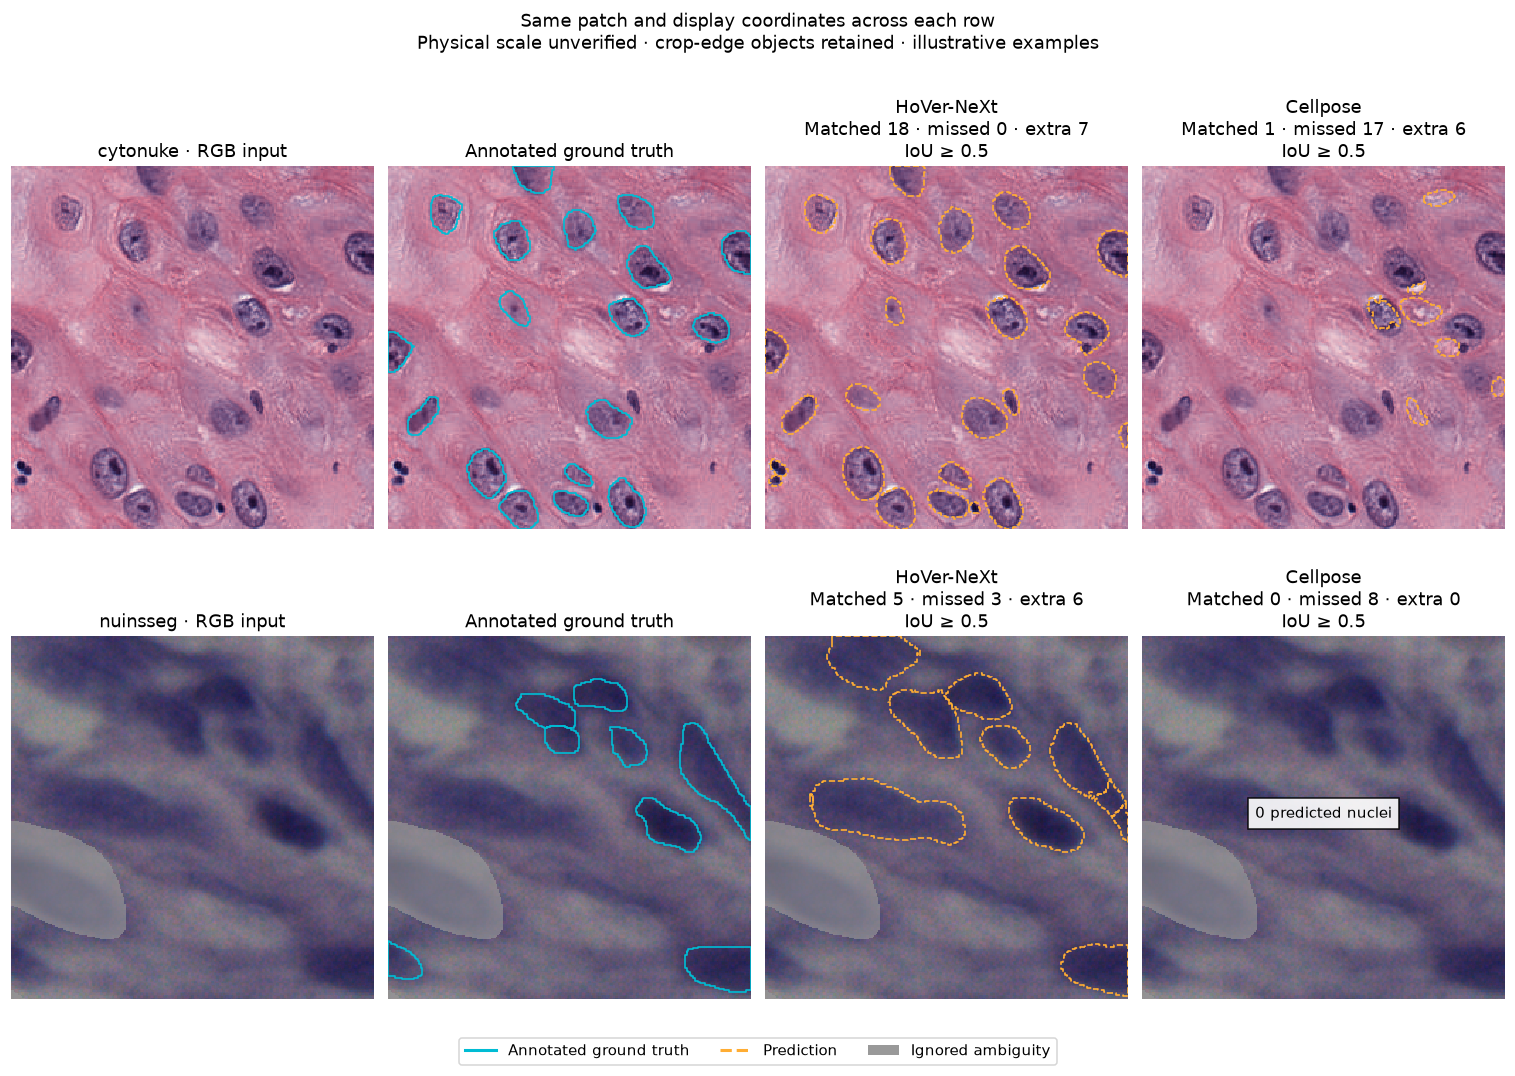

In [2]:
for name in patches:
    for model in ('hovernext', 'cellpose'):
        baseline[name, model] = run_prediction(demo, name, model)

fig = plot_model_comparison(patches, baseline)
fig.savefig(demo['out'] / 'model_comparison.png')
plt.show()

## 3. Foreground overlap versus individual nuclei

**One evaluation region:** ambiguity pixels are removed from both masks. An ID with no remaining pixels is ignored; partially visible IDs retain their identity. CytoNuke has no separate ambiguity mask here. Crop-edge objects remain included, so metrics concern visible crop objects rather than reconstructed full-slide cells.

Foreground Dice measures occupied pixels and cannot detect all splits or merges. Instance matching is **one-to-one at IoU ≥0.5**, maximizing valid match count and then total IoU. The table uses evaluated IDs with included pixels; undefined denominators remain unavailable. All-object counts, edge counts and additional error metrics are retained in the exported comparison CSV.

In [3]:
rows = [comparison_row(name, model, attempt['evaluation'])
        for (name, model), attempt in baseline.items()]
comparison = pd.DataFrame(rows)
display(comparison[['patch', 'model', 'reference_evaluated', 'prediction_evaluated',
                    'matched', 'missed', 'extra', 'precision', 'recall',
                    'instance_f1', 'foreground_dice']].rename(columns={
    'reference_evaluated': 'ground_truth_evaluated'}).round(3))

,patch,model,ground_truth_evaluated,prediction_evaluated,matched,missed,extra,precision,recall,instance_f1,foreground_dice
0,cytonuke,hovernext,18,25,18,0,7,0.720,1.000,0.837,0.829
1,cytonuke,cellpose,18,7,1,17,6,0.143,0.056,0.080,0.064
2,nuinsseg,hovernext,8,11,5,3,6,0.455,0.625,0.526,0.616
3,nuinsseg,cellpose,8,0,0,8,0,NaN,0.000,0.000,0.000


### Prediction postprocessing: minimum area and crop boundaries

A minimum object area can remove small false positives, but it can also remove true small nuclei. This fixed **128-input-pixel** example is chosen from the raw prediction sizes, before consulting ground truth: two interior predictions are about 50 pixels and the smallest frame-touching prediction is 76 pixels. These PNGs have no verified physical scale, so this is an illustrative pixel threshold, not a universal biological cutoff. The cutoff is not validated or optimized for annotation agreement.

Both variants use the same raw CytoNuke HoVer-NeXt mask. Area-only filtering removes IDs below the cutoff; edge-aware filtering protects small IDs that touch the original patch frame. Filtering sees predictions only. Ground truth enters the unchanged one-to-one IoU ≥0.5 evaluation afterwards. Protected edge objects can still be false positives; their partial visible area alone is insufficient evidence for removal.

Border nuclei may be truncated. Overlapping patches can provide additional context, but whole-slide inference still needs instance reconciliation in global coordinates, including merging or deduplication, before final size filtering. Overlap alone does not fix truncation or double counting. This block applies both filters to existing single-patch predictions and retains the raw mask.

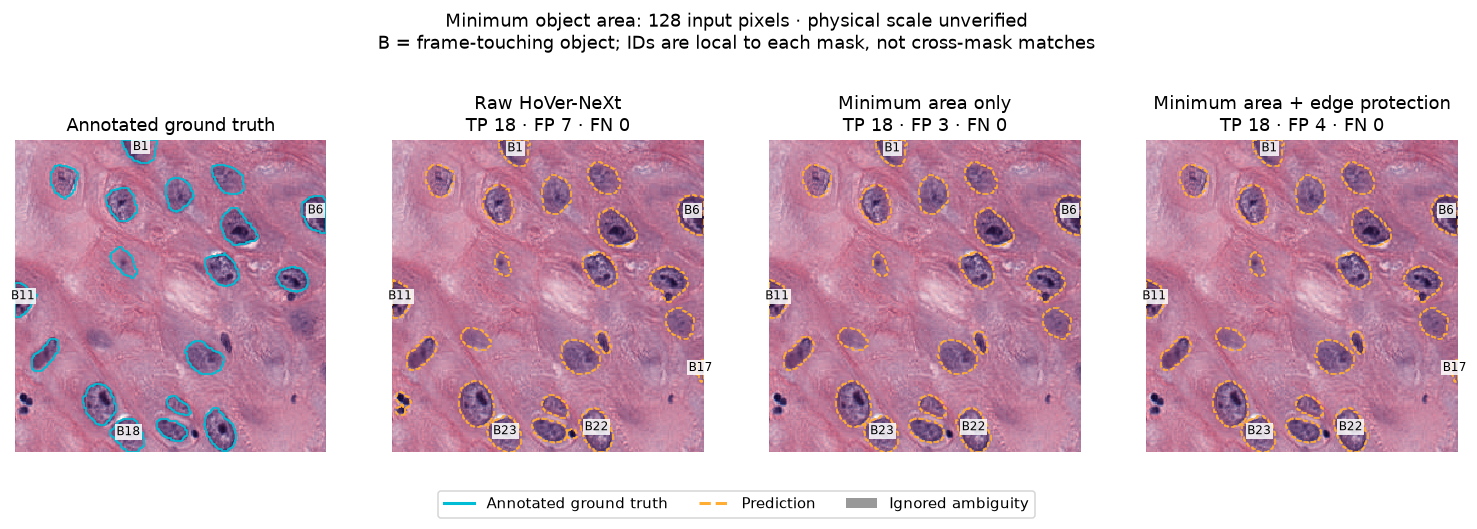

,variant,TP,FP,FN,removed_ids,protected_ids
0,raw,18,7,0,[],[]
1,area_only,18,3,0,"[17, 19, 21, 25]",[]
2,edge_aware,18,4,0,"[19, 21, 25]",[17]


Protected small border predictions: [17]; IDs scored as false positives under this annotation policy: [17].


In [4]:
raw = baseline['cytonuke', 'hovernext']
postprocessed = postprocess_prediction(demo, raw, min_area=128)
fig = plot_postprocessing(patches['cytonuke'], raw, postprocessed)
fig.savefig(demo['out'] / 'postprocessing_comparison.png')
plt.show()

post_rows = []
for label, result in [('raw', raw), *postprocessed.items()]:
    metrics = result['evaluation']
    policy = result.get('filter', {})
    post_rows.append({'variant': label, 'TP': metrics['matched'], 'FP': metrics['extra'],
                     'FN': metrics['missed'], 'removed_ids': policy.get('removed_ids', []),
                     'protected_ids': policy.get('protected_ids', [])})
display(pd.DataFrame(post_rows))

protected = set(postprocessed['edge_aware']['filter']['protected_ids'])
protected_fp = protected & set(raw['evaluation']['extra_ids'])
print(f'Protected small border predictions: {sorted(protected)}; '
      f'IDs scored as false positives under this annotation policy: {sorted(protected_fp)}.')


## 4. One controlled experiment: input polarity

Keep the NuInsSeg RGB, crop, weights, grayscale channel, diameter=17, thresholds and normalization percentiles fixed. Change **only `invert=False → True`**. This predeclared experiment does not choose a best setting by searching the annotations.

The first two columns show the pinned Cellpose library's selected and percentile-normalized channel before diameter rescaling. Display values are clipped to [0,1]; inference values are unchanged for display. The last two columns overlay the same ground truth and each prediction on the original RGB. Compare matches, missed/extra nuclei and overlap, not just whether more objects appeared.

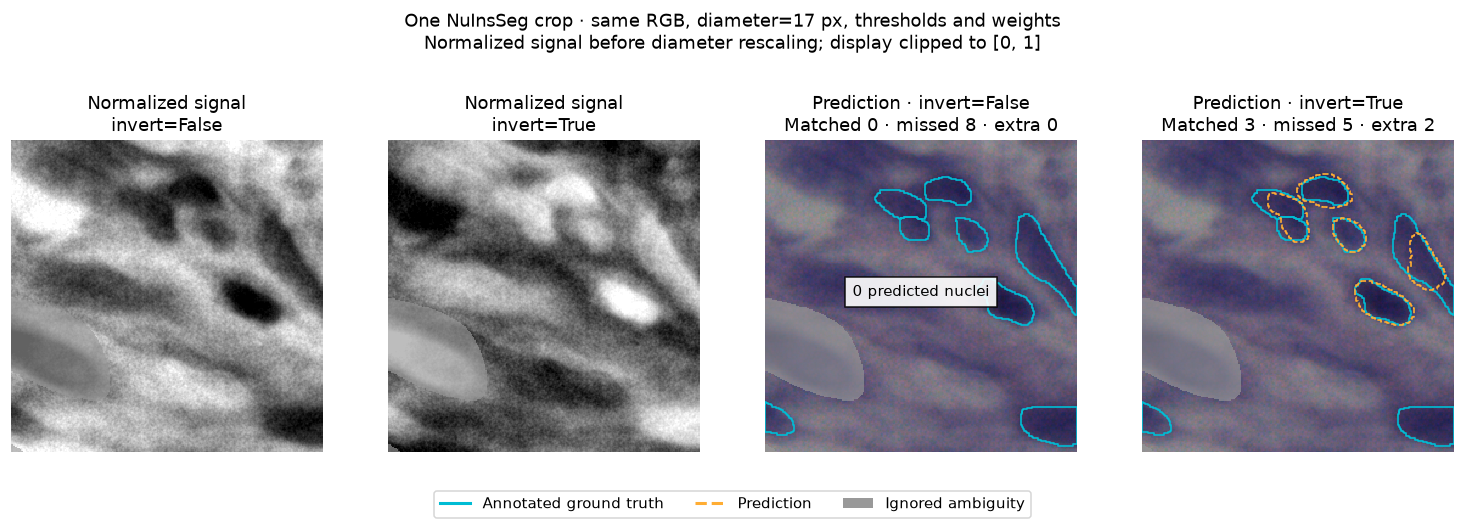

,model,prediction_evaluated,matched,missed,extra,instance_f1,foreground_dice
0,baseline,0,0,8,0,0.000,0.000
1,polarity experiment,5,3,5,2,0.462,0.669


In [5]:
polarity = run_prediction(demo, 'nuinsseg', 'cellpose', invert=True)
control = baseline['nuinsseg', 'cellpose']
assert np.allclose(polarity['normalized_input'], 1 - control['normalized_input'], atol=1e-6)
assert control['metadata']['patch']['rgb_sha256'] == polarity['metadata']['patch']['rgb_sha256']
old_settings, new_settings = control['metadata']['settings']['settings'], polarity['metadata']['settings']['settings']
assert {k: v for k, v in old_settings.items() if k not in ('invert', 'normalize')} == {
        k: v for k, v in new_settings.items() if k not in ('invert', 'normalize')}
assert {k: v for k, v in old_settings['normalize'].items() if k != 'invert'} == {
        k: v for k, v in new_settings['normalize'].items() if k != 'invert'}
fig = plot_polarity(patches['nuinsseg'], control, polarity)
fig.savefig(demo['out'] / 'polarity_comparison.png')
plt.show()
display(pd.DataFrame([comparison_row('nuinsseg', label, a['evaluation'])
        for label, a in [('baseline', control), ('polarity experiment', polarity)]])[
        ['model', 'prediction_evaluated', 'matched', 'missed', 'extra', 'instance_f1', 'foreground_dice']].round(3))

## 5. Annotation conversion and saved results

The shared converter exports COCO polygons or masks as image-coordinate GeoJSON and uint32 instance TIFFs. GeoJSON preserves original COCO polygons; TIFFs use the declared last-wins raster overlap policy. NuInsSeg uses the authors-recommended modified integer labels.

The export helper saves the annotations, model settings, metrics and prediction attempts in a fresh report directory. See the [conversion format](../docs/annotation-conversion.md) and [study evaluation guide](../docs/segmentation-evaluation.md).

In [6]:
report = export_demo(demo)
print('Saved report:', report)
print('Retained prediction attempts:', len(demo['attempts']))
print('Original source files and crop arrays verified unchanged.')

Saved report: /Users/irina/Projects/digital-pathology-demo/outputs/pipeline-audit-20261103/segmentation-dedup-publish-validation/runs/20261103T184725Z_crbelr6s/reports/export_p28e8psg
Retained prediction attempts: 5
Original source files and crop arrays verified unchanged.


## Pretrained model provenance

| Model used | Training strategy | Training data |
| --- | --- | --- |
| **HoVer-NeXt PanNuke Tiny, split 1** (`pannuke_convnextv2_tiny_1`) | Supervised joint nucleus-instance segmentation and nucleus-type classification. The ConvNeXt-V2 Tiny encoder first uses FCMAE self-supervision, then supervised ImageNet fine-tuning. | Encoder: ImageNet-1k for FCMAE, then ImageNet-22k → ImageNet-1k. Released pathology model: **PanNuke**. [Checkpoint](https://zenodo.org/records/10635618), [training code](https://github.com/digitalpathologybern/hover_next_train), [exact encoder](https://huggingface.co/timm/convnextv2_tiny.fcmae_ft_in22k_in1k). |
| **Cellpose legacy nuclei** (`nucleitorch_0`), executed with Cellpose 3.1.1.2 | Supervised residual U-Net-style foreground/flow prediction from instance masks; flows reconstruct nuclei. Training normalizes nucleus diameter to 17 pixels. | Original nuclei corpus: Data Science Bowl/Kaggle, additional Kaggle images, ISBI 2009 and MoNuSeg. No separate ImageNet/SSL initialization is documented for this checkpoint. [Original paper, Extended Data Fig. 7](https://www.nature.com/articles/s41592-020-01018-x), [checkpoint mapping](https://cellpose.readthedocs.io/en/v3.1.1.1/models.html#nucleus-model-nuclei), [author training description](https://pmc.ncbi.nlm.nih.gov/articles/PMC11903308/). |

Both models perform inference here; neither is fine-tuned on CytoNuke or NuInsSeg. Cellpose 3.1.1.2 is the software version, not the cyto3 or Cellpose-SAM checkpoint. Exhaustive image-level training manifests are unavailable, so overlap with demo inputs has not been ruled out. Pretraining provenance does not establish generalization to these examples.
